# Q2D | Train Linear Regression

> *Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization: try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.*

---

#### IMPORTANT

This dataset has no `train` / `test` split of its own, so the same chronological split as Q2B and Q2C is made at the top of this notebook: the earliest 584 days are `train` and the latest 147 days are `test`. Every model below is fit and scored on the training rows only, so no modeling decision is influenced by the test data (`data snooping`).

# Answer Summary

**Setup:** every model is one pipeline scored with 4-fold cross validation on the same folds. The folds are time-ordered (each trains on the days before its validation block and validates on the next 46 days), because the test rows are the days after the training period. The metric is rmse, in `Rentals` units. A model only counts as better when its rmse gain is more than 1 SE of the per-fold differences, and ties go to the simpler model. Every `random_state` is set to 42.

**Closed form, SGD and the selected model**

| Model | rmse | train rmse | Against the row above |
|---|---|---|---|
| Dummy (always the mean) | 2521.601 | 1476.256 | |
| Closed form, 11 attributes as stored | 1144.861 | 709.966 | better |
| Closed form, selected features | 789.225 | 569.933 | better |
| SGD, no penalty, default `eta0=0.01` | 808.959 | 574.251 | worse |
| SGD, no penalty, `eta0=0.0001` | 791.910 | 570.051 | better |
| Lasso SGD, `alpha=0.001`, `eta0=0.0001` (selected) | 792.708 | 570.165 | tie |

train rmse is the same model scored on its own training rows. It sits well below rmse for every model, the Dummy included, because each fold validates on later days at a different `Rentals` level.

- **The gain comes from the feature set.** FeelsLike's flat top and Month as sine / cosine hold up with the other attributes in the model, and IsWorkday and IsHoliday are dropped. Several of Q2C's choices do not hold on these folds: Month one-hot, Humidity's hinge and Weather one-hot add nothing, and both redundant pairs stay whole.
- **SGD needs a small learning rate to get close to closed form.** At the default `eta0=0.01` it stops short, mostly in the two temperature coefficients. At 0.0001 it comes within 2.685 of closed form, at the cost of 219,994 epochs against 201.
- **Regularization does not help.** Lasso at `alpha` 0.001 and 0.01 ties with plain SGD and barely moves any coefficient. Ridge and Elastic Net are worse at every `alpha` and underfit as it grows: at 0.1 rmse is 1035.125 and 1016.807, and Ridge moves the Temp coefficient from -1327.5 to 109.6.
- **The selected model is Lasso at `alpha=0.001`,** the smaller of the two tied penalties. It is selected because the question asks for a regularized model, not because the penalty helps. Fit on all 584 training rows it runs 219,994 epochs, with a training rmse of 613.372.
- **The loss by epoch shows no overfitting from training longer.** Validation rmse falls from 5856.281 at epoch 1 to 798.340 at epoch 10,000 and is lowest at the last of the 30,000 epochs (791.022), with training rmse flat at 571.039.

**Carried forward:** the fitted pipeline, saved as `linear_regression.joblib`. It takes the 11 attributes as they are stored, and its cross validated rmse of 792.708 is the estimate for days it has not seen.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import OneHotEncoder

from Q2.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	SCORING,
	FEATURES,
	PIPELINES,
)

from Q2.utils import (
	chronological_split,
	make_time_folds,
	Q2_FEATURES,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


`test_df` is not used again in this notebook.

# Setup

## Attributes

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

# the same 11 attributes as Q2C. ID, Date, Casual and Registered are left out, as concluded in Q2B
ATTRIBUTES = CONTINUOUS + BINARY + MULTI_LEVEL

X = train_df[ATTRIBUTES]
y = train_df[TARGET]

print(f"rows: {len(X)} | attributes: {len(ATTRIBUTES)} | missing values: {int(X.isna().sum().sum())}")

rows: 584 | attributes: 11 | missing values: 0


## Folds

In [5]:
FOLDS = make_time_folds(train_df, date_col="Date", n_splits=CV_SPLITS, validation_size=CV_TEST_SIZE)

fold_rows = []
for train_labels, validation_labels in FOLDS.folds:
	train_rows, validation_rows = train_df.loc[train_labels], train_df.loc[validation_labels]
	# a one-hot encoder fails on a level it did not see in training
	for attribute in MULTI_LEVEL:
		assert set(validation_rows[attribute]) <= set(train_rows[attribute]), f"{attribute} has a level only in validation"
	fold_rows.append({
		"train rows": len(train_rows),
		"train rows in Year 1": int((train_rows["Year"] == 1).sum()),
		"validation rows": len(validation_rows),
		"validation first date": f"{validation_rows['Date'].min():%Y-%m-%d}",
		"validation last date": f"{validation_rows['Date'].max():%Y-%m-%d}",
	})

pd.DataFrame(fold_rows, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))

,train rows,train rows in Year 1,validation rows,validation first date,validation last date
fold,,,,,
1,400,35,46,2012-02-05,2012-03-21
2,446,81,46,2012-03-22,2012-05-06
3,492,127,46,2012-05-07,2012-06-21
4,538,173,46,2012-06-22,2012-08-06


## Shapes

In [6]:
ONE_HOT = OneHotEncoder(drop="first", sparse_output=False)

# "shape" is the form Q2C carried forward for each attribute. Any other name is an alternative Q2C also carried forward.
#   LowHinge:  [max(0, t - x)], a flat top: 0 at or above t, growing as x falls below it
#   HighHinge: [max(0, x - t)], 0 at or below t, growing as x rises above it
#   ONE_HOT:   one 0 / 1 column per level, with the first level left out as the reference
#   Cyclical:  [sin(2π·x / 12), cos(2π·x / 12)]
SHAPES = {
	"FeelsLike": {"shape": FEATURES.LowHinge(t=0.60)},
	"Temp": {"shape": FEATURES.LowHinge(t=0.58)},
	"Humidity": {"shape": FEATURES.HighHinge(t=0.70)},
	"Month": {"shape": ONE_HOT, "sine / cosine": Q2_FEATURES.Cyclical(period=12)},
	"Season": {"shape": ONE_HOT},
	"Weather": {"shape": ONE_HOT},
}


def build(choice, estimator, *, scale=False):
	"""One pipeline for a feature choice and a model: features > (scaler) > model.

	Args:
		choice: What each attribute contributes: "raw", "drop" or the name of one of its SHAPES. Attributes left
			out are "raw", so {} is the 11 attributes as they are stored.
		estimator: Final model.
		scale: Standardize the feature columns before the model.
	"""
	return PIPELINES.attribute_pipeline(estimator, attributes=ATTRIBUTES, shapes=SHAPES, choice=choice, scale=scale)


# the feature columns each shape builds
shape_columns = {}
for attribute, shapes in SHAPES.items():
	for name in shapes:
		only_this = {other: "drop" for other in ATTRIBUTES if other != attribute} | {attribute: name}
		features = build(only_this, LinearRegression())["features"].fit(X)
		shape_columns[(attribute, name)] = ", ".join(features.get_feature_names_out())

with pd.option_context("display.max_colwidth", None):
	display(pd.Series(shape_columns).rename_axis(["attribute", "shape"]).to_frame("feature columns"))

feature columns
attribute shape                                                                                                              
FeelsLike shape                                                                                      FeelsLike__low_hinge_0.6
Temp      shape                                                                                          Temp__low_hinge_0.58
Humidity  shape                                                                                           Humidity__hinge_0.7
Month     shape          Month_2, Month_3, Month_4, Month_5, Month_6, Month_7, Month_8, Month_9, Month_10, Month_11, Month_12
          sine / cosine                                                                                Month__sin, Month__cos
Season    shape                                                                                  Season_2, Season_3, Season_4
Weather   shape                                                                                          Weather_2, Weather_3

## Scoring

In [7]:
RESULTS = {}


def score(name, pipeline):
	"""Score a pipeline on FOLDS and keep its per-fold scores in RESULTS under name.

	Args:
		name: Row label of the model in every table.
		pipeline: Model or pipeline to score.
	"""
	RESULTS[name] = PIPELINES.evaluate_pipeline(pipeline, X=X, y=y, folds=FOLDS, return_train_score=True)


def table(names, *, baseline, holm=False):
	"""Results table of the named models, with the noise threshold against baseline.

	Args:
		names: Models to show, each already scored with score.
		baseline: Name of the model the rmse difference is measured against. It must be in names.
		holm: Add the Holm adjusted p and the "significant" verdict.
	"""
	return SCORING.results_df({name: RESULTS[name] for name in names}, baseline=baseline, holm=holm)

# Method

Every model is one `Pipeline` from `build(choice, estimator)`: features, (scaler), model. `choice` sets each attribute to `"raw"`, `"drop"` or the name of one of its shapes in `SHAPES`, and every step is fit inside each training fold.

- **Rows:** no attribute has a missing value, so every model uses all 584 training rows.
- **Folds:** 4 time-ordered folds, built once and used by every model. Each fold trains on every day before its validation block and validates on the next 46 days.
- **Why time-ordered:** the test rows are the days after the training period. Q2C scored its shapes on shuffled folds, which hold days inside that period, so every gain it carried forward is tested again here.
- **Why validation starts in 2012:** a fold that trains on the first year only sees a single value of `Year`. Every training fold here holds all of the first year and at least 35 days of the second.
- **Limit:** 4 folds give 4 differences per comparison, so the SE below is a rough estimate and **significant** is hard to reach.
- **Metric:** rmse. It is in `Rentals` units, counts large misses more than small ones, and is the squared error a linear regression minimizes. mae and r2 are reported next to it, and `train rmse mean` is the same model scored on its own training rows.
- **Shapes:** `SHAPES` holds the form Q2C carried forward for each attribute (`"shape"`) and its alternative for Month, with thresholds fixed at Q2B's values. Those thresholds were found on all the training rows, so a shape's gain is slightly optimistic.
- **Scaling:** SGD models standardize the feature columns. Closed form does not need it. `Rentals` stays in its own units.
- **Seed:** the folds are not shuffled, so they need no seed. Every `random_state` in a pipeline is set to 42 before it is fit, so a rerun gives the same numbers.

**Noise threshold (Δrmse vs the baseline)**

- Δ is the mean of the per-fold rmse differences d (model minus baseline). Negative means lower error than the baseline.
- The folds share most of their training rows, so the SE of Δ uses the Nadeau and Bengio correction: `SE = sqrt(var(d) · (1/folds + n_test/n_train))`. `Δ / SE` is the corrected t statistic and `p` its one-sided p-value.
- `verdict`:
  - **within noise:** Δ is within 1 SE of 0.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE.
  - **significant** (tables with `p (Holm)` only): the Holm adjusted p is below 0.05, adjusted over that table's rows.

**Decisions**

- **Ties go to the simpler model.** A row that adds something (a column, a penalty) is kept only if it is **candidate** or **significant**. A row that removes something is kept unless it is **worse**.
- **Each section's choice is the next section's baseline.**

# Baselines

A model that always predicts the mean `Rentals`, then closed form linear regression on the 11 attributes as they are stored, with the category codes entered as numbers.

## Dummy Regressor

In [8]:
score("Dummy", DummyRegressor(strategy="mean"))
display(table(["Dummy"], baseline="Dummy"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Dummy,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Dummy,2521.601,670.512,1476.256,2317.678,765.003,-5.379,4.344,0.0,NaN,NaN,NaN,baseline,4


## Closed Form Linear Regression

`LinearRegression` solves the least squares problem in closed form (scikit-learn uses an SVD based solver): one direct solve, with no iterations and no learning rate.

In [9]:
score("Closed form, 11 raw", build({}, LinearRegression()))
display(table(["Dummy", "Closed form, 11 raw"], baseline="Dummy"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Dummy,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Closed form, 11 raw",1144.861,148.131,709.966,916.270,162.713,-0.246,0.811,-1376.74,358.286,-3.843,0.016,candidate,4
Dummy,2521.601,670.512,1476.256,2317.678,765.003,-5.379,4.344,0.00,NaN,NaN,NaN,baseline,4


## Results

- **Closed form on the 11 attributes is far better than predicting the mean.** rmse falls from 2521.601 to 1144.861 (Δ / SE -3.843) and mae from 2317.678 to 916.270.
- **Validation rmse sits well above training rmse, and that is not overfitting alone.** Closed form scores 709.966 on its own training rows against 1144.861, and the Dummy, which only fits a mean, shows the same gap (1476.256 against 2521.601). The later days sit at a different `Rentals` level.
- **r2 is negative for both models** (-5.379 and -0.246). It compares each model with the mean of the validation block itself, so rmse is the number to read on these folds.

**Carry forward**

- **Closed form, 11 raw** (rmse 1144.861), as the baseline for the Feature Set section.

# Feature Set

Which feature columns the model is given. Every model in this section is closed form `LinearRegression`, which has no learning rate or seed to add noise to the comparison.

## Shapes and Encodings, One at a Time

Each row changes one attribute to its form from `SHAPES` and leaves the other ten as they are stored, so a gain here is one that holds with the other attributes in the model.

In [10]:
ONE_SHAPE = {f"Shape: {attribute}": {attribute: "shape"} for attribute in SHAPES}

for name, choice in ONE_SHAPE.items():
	score(name, build(choice, LinearRegression()))

display(table(["Closed form, 11 raw", *ONE_SHAPE], baseline="Closed form, 11 raw", holm=True))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, 11 raw",Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,,
Shape: FeelsLike,836.799,126.001,595.798,676.107,140.350,0.402,0.177,-308.062,99.660,-3.091,0.027,0.134,candidate,4
Shape: Temp,854.630,122.936,599.303,694.696,151.953,0.357,0.246,-290.231,83.888,-3.460,0.020,0.122,candidate,4
Shape: Season,962.654,54.414,654.746,750.142,32.554,0.147,0.489,-182.206,89.069,-2.046,0.067,0.267,candidate,4
Shape: Month,999.056,57.489,616.032,773.998,59.975,0.072,0.556,-145.804,82.821,-1.760,0.088,0.267,candidate,4
Shape: Weather,1144.248,120.283,691.829,924.759,141.291,-0.229,0.756,-0.613,17.141,-0.036,0.487,0.974,within noise,4
"Closed form, 11 raw",1144.861,148.131,709.966,916.270,162.713,-0.246,0.811,0.000,NaN,NaN,NaN,NaN,baseline,4
Shape: Humidity,1148.477,146.848,703.404,924.890,173.198,-0.246,0.787,3.616,6.491,0.557,0.692,0.974,within noise,4


### Results

- **Four forms help with the other attributes in the model.** FeelsLike's flat top (rmse 836.799), Temp's flat top (854.630), Season one-hot (962.654) and Month one-hot (999.056) are all candidates against 1144.861. None is significant: the lowest `p (Holm)` is 0.122.
- **They are the two redundant pairs.** FeelsLike is ahead of Temp, as in Q2C. Season is ahead of Month here, the reverse of Q2C's order.
- **Humidity's hinge and Weather one-hot add nothing here.** Both are within noise (changes of 3.616 and -0.613 against SEs of 6.491 and 17.141), although both were gains in Q2C with one attribute in the model.

**Carry forward**

- **FeelsLike's flat top and Month one-hot,** Q2C's first choice of each redundant pair, to be combined in one model. Temp's flat top and Season one-hot are swapped in after that.

**Ignore**

- **Humidity's hinge and Weather one-hot.** Those attributes stay as they are stored.

## Combined

The first choice of each redundant pair in one model: `2 shapes` changes FeelsLike to its flat top and Month to one-hot, and leaves the other nine attributes as they are stored.

In [11]:
TWO_SHAPES = {"FeelsLike": "shape", "Month": "shape"}

score("2 shapes", build(TWO_SHAPES, LinearRegression()))
display(table(["Closed form, 11 raw", "2 shapes"], baseline="Closed form, 11 raw"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, 11 raw",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
2 shapes,851.032,75.805,553.896,639.761,72.369,0.381,0.181,-293.828,103.531,-2.838,0.033,candidate,4
"Closed form, 11 raw",1144.861,148.131,709.966,916.270,162.713,-0.246,0.811,0.000,NaN,NaN,NaN,baseline,4


### One Shape Taken Back Out

Each row puts one of the two attributes back to its stored column, which leaves the other shape on its own. Both are already scored: `Shape: FeelsLike` (Month back to its code) and `Shape: Month` (FeelsLike back to its raw value). A shape earns its place if taking it out is **worse**.

In [12]:
display(table(["2 shapes", "Shape: FeelsLike", "Shape: Month"], baseline="2 shapes"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs 2 shapes,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Shape: FeelsLike,836.799,126.001,595.798,676.107,140.350,0.402,0.177,-14.233,55.399,-0.257,0.407,within noise,4
2 shapes,851.032,75.805,553.896,639.761,72.369,0.381,0.181,0.000,NaN,NaN,NaN,baseline,4
Shape: Month,999.056,57.489,616.032,773.998,59.975,0.072,0.556,148.024,75.241,1.967,0.928,worse,4


### Results

- **The two shapes together beat the attributes as stored.** `2 shapes` lowers rmse from 1144.861 to 851.032 (Δ / SE -2.838).
- **FeelsLike's flat top earns its place.** Taking it back out is worse: 999.056, a change of 148.024 against an SE of 75.241.
- **Month one-hot does not.** Taking it back out is within noise and scores lower (836.799 against 851.032). Its 11 columns fit the training rows better (training rmse 553.896 against 595.798) without helping the days that follow.

**Carry forward**

- **`Shape: FeelsLike`** (rmse 836.799): FeelsLike's flat top, with the other ten attributes as they are stored.

**Ignore**

- **Month one-hot.** It ties with the Month code and needs 11 columns in place of 1.

## Alternatives

Month one-hot did not hold, so the other forms are tried in `Shape: FeelsLike`. Each row changes one more thing:

- **Month, sine / cosine:** 2 columns in place of the Month code.
- **Season, one-hot:** 3 columns in place of the Season code.
- **Month, one-hot:** `2 shapes` from above.
- **Temp's flat top in place of FeelsLike's:** `Shape: Temp` from above.

In [13]:
FLAT_TOP = {"FeelsLike": "shape"}

ALTERNATIVES = {
	"Flat top, Month sine / cosine": {**FLAT_TOP, "Month": "sine / cosine"},
	"Flat top, Season one-hot": {**FLAT_TOP, "Season": "shape"},
}

for name, choice in ALTERNATIVES.items():
	score(name, build(choice, LinearRegression()))

display(table(["Shape: FeelsLike", *ALTERNATIVES, "2 shapes", "Shape: Temp"], baseline="Shape: FeelsLike"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Shape: FeelsLike,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Flat top, Month sine / cosine",792.493,75.898,567.823,596.086,75.948,0.460,0.163,-44.307,30.652,-1.445,0.122,candidate,4
"Flat top, Season one-hot",807.391,36.649,578.117,624.327,40.797,0.432,0.207,-29.408,56.375,-0.522,0.319,within noise,4
Shape: FeelsLike,836.799,126.001,595.798,676.107,140.350,0.402,0.177,0.000,NaN,NaN,NaN,baseline,4
2 shapes,851.032,75.805,553.896,639.761,72.369,0.381,0.181,14.233,55.399,0.257,0.593,within noise,4
Shape: Temp,854.630,122.936,599.303,694.696,151.953,0.357,0.246,17.831,28.436,0.627,0.712,within noise,4


### Results

- **Sine / cosine is the calendar form that helps.** It lowers rmse from 836.799 to 792.493, a change of -44.307 against an SE of 30.652, with 2 columns.
- **Neither one-hot clears the threshold.** Season one-hot scores lower than the baseline (807.391) but is within noise (SE 56.375), and Month one-hot scores higher (851.032).
- **FeelsLike stays ahead of Temp.** Temp's flat top in place of FeelsLike's is within noise (854.630, a change of 17.831 against an SE of 28.436), so Q2C's first choice is kept.

**Carry forward**

- **`Flat top, Month sine / cosine`** (rmse 792.493).

**Ignore**

- **Season one-hot, Month one-hot and Temp's flat top.** All three are within noise.

## Drops

Each row removes attributes from `Flat top, Month sine / cosine`:

- **Weekday, IsWorkday, IsHoliday and Wind:** for each of them Q2B listed a drop, as its first suggestion or as the fallback. One row also drops IsWorkday and IsHoliday together.
- **Temp and Season:** the member of each redundant pair that is still in the model as it is stored.

In [14]:
SHAPED = {"FeelsLike": "shape", "Month": "sine / cosine"}

DROPS = {
	"Drop Weekday": {**SHAPED, "Weekday": "drop"},
	"Drop IsWorkday": {**SHAPED, "IsWorkday": "drop"},
	"Drop IsHoliday": {**SHAPED, "IsHoliday": "drop"},
	"Drop Wind": {**SHAPED, "Wind": "drop"},
	"Drop IsWorkday + IsHoliday": {**SHAPED, "IsWorkday": "drop", "IsHoliday": "drop"},
	"Drop Temp": {**SHAPED, "Temp": "drop"},
	"Drop Season": {**SHAPED, "Season": "drop"},
}

for name, choice in DROPS.items():
	score(name, build(choice, LinearRegression()))

display(table(["Flat top, Month sine / cosine", *DROPS], baseline="Flat top, Month sine / cosine"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Flat top, Month sine / cosine",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Drop IsWorkday + IsHoliday,789.225,76.185,569.933,597.399,68.178,0.465,0.160,-3.268,0.897,-3.645,0.018,candidate,4
Drop IsWorkday,790.270,75.888,568.297,597.049,73.025,0.462,0.166,-2.222,2.009,-1.106,0.175,candidate,4
Drop IsHoliday,791.426,77.840,569.003,595.360,72.864,0.464,0.153,-1.067,3.454,-0.309,0.389,within noise,4
"Flat top, Month sine / cosine",792.493,75.898,567.823,596.086,75.948,0.460,0.163,0.000,NaN,NaN,NaN,baseline,4
Drop Weekday,805.067,86.791,573.566,605.775,79.128,0.445,0.158,12.574,7.262,1.732,0.909,worse,4
Drop Wind,828.396,81.867,593.126,619.492,64.677,0.416,0.155,35.903,10.829,3.316,0.977,worse,4
Drop Season,867.331,173.313,625.360,683.159,175.955,0.364,0.205,74.839,65.382,1.145,0.832,worse,4
Drop Temp,896.685,73.251,605.451,695.741,112.902,0.264,0.383,104.192,49.408,2.109,0.937,worse,4


### Results

- **IsWorkday and IsHoliday add nothing.** Dropping either one is not worse, and dropping both gives the lowest rmse in the table: 789.225, a change of -3.268 against an SE of 0.897.
- **Weekday and Wind earn their place,** although Q2B listed a drop for both. Without Weekday rmse rises to 805.067 and without Wind to 828.396, both worse.
- **Both redundant pairs stay whole,** against Q2C's "keep one of each". Dropping Temp (896.685) or Season (867.331) is worse, so raw Temp adds to FeelsLike's flat top and the Season code adds to Month's sine / cosine.

**Carry forward**

- **`Drop IsWorkday + IsHoliday`** (rmse 789.225) as the feature set for every model below: FeelsLike's flat top, Month as sine / cosine, and Temp, Humidity, Wind, Year, Season, Weekday and Weather as they are stored.

**Ignore**

- **Dropping Weekday, Wind, Temp or Season.** Each one is worse.

# SGD

The same feature set fit by stochastic gradient descent, compared with closed form, then the learning rate.

In [15]:
# the feature set carried forward from the Feature Set section
FEATURE_CHOICE = {"FeelsLike": "shape", "Month": "sine / cosine", "IsWorkday": "drop", "IsHoliday": "drop"}
assert FEATURE_CHOICE == DROPS["Drop IsWorkday + IsHoliday"]

# the closed form model on that feature set, under the name used from here on (nothing is scored again)
RESULTS["Closed form, selected features"] = RESULTS["Drop IsWorkday + IsHoliday"]

# epoch limit of every SGD model, raised from scikit-learn's default of 1,000
MAX_ITER = 1_000_000

## SGD vs Closed Form

`SGDRegressor` with no penalty and scikit-learn's default learning rate (`eta0=0.01`), on standardized feature columns. It reaches its coefficients through repeated small steps, where closed form solves for them directly.

`max_iter` is raised to 1,000,000 epochs for every SGD model, so each one stops when its training loss stops improving and not at the limit.

In [16]:
score("SGD", build(FEATURE_CHOICE, SGDRegressor(penalty=None, max_iter=MAX_ITER), scale=True))
display(table(["Closed form, selected features", "SGD"], baseline="Closed form, selected features"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, selected features",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Closed form, selected features",789.225,76.185,569.933,597.399,68.178,0.465,0.160,0.000,NaN,NaN,NaN,baseline,4
SGD,808.959,76.280,574.251,622.753,75.558,0.438,0.169,19.734,1.021,19.332,1.0,worse,4


In [17]:
# both fit once on all the training rows, on standardized columns so the coefficients are comparable
closed_form_fit = build(FEATURE_CHOICE, LinearRegression(), scale=True).fit(X, y)
sgd_fit = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SGDRegressor(penalty=None, max_iter=MAX_ITER), scale=True)).fit(X, y)

coefficients = pd.DataFrame(
	{"closed form": closed_form_fit["model"].coef_, "SGD": sgd_fit["model"].coef_},
	index=closed_form_fit[:-1].get_feature_names_out(),
)
coefficients["difference"] = coefficients["SGD"] - coefficients["closed form"]

print(f"SGD epochs run: {sgd_fit['model'].n_iter_}")
display(coefficients.round(1))

SGD epochs run: 201


,closed form,SGD,difference
Temp,-1370.8,-1120.6,250.2
FeelsLike__low_hinge_0.6,-2031.4,-1815.7,215.7
Humidity,-234.5,-221.5,13.0
Wind,-197.2,-199.9,-2.7
Year,942.4,941.0,-1.4
Season,432.7,452.6,19.9
Month__sin,-48.8,-3.8,45.0
Month__cos,-371.2,-342.8,28.4
Weekday,101.9,101.1,-0.8
Weather,-296.5,-295.9,0.6


### Results

- **At the default learning rate, SGD stops short of closed form.** Its rmse is 808.959 against 789.225, a change of 19.734 against an SE of 1.021, and its training rmse is higher too (574.251 against 569.933).
- **The gap is in the two temperature columns.** After 201 epochs eight of the ten coefficients are within 45.0 of closed form's, but Temp is at -1120.6 against -1370.8 and FeelsLike's flat top at -1815.7 against -2031.4. These are the pair Q2C found redundant (r = 0.997).

**Carry forward**

- **`SGD`** (rmse 808.959) as the baseline for the learning rate, since the question focuses on SGD from here.

## Learning Rate

`eta0` is the initial learning rate, the size of the first steps. Each row changes only `eta0`, with the penalty still off. `SGD` already uses 0.01, scikit-learn's default, so it is the baseline and the 0.01 row.

In [18]:
ETA0S = {f"SGD, eta0={eta0}": eta0 for eta0 in LEARNING_RATES if eta0 != 0.01}

for name, eta0 in ETA0S.items():
	score(name, build(FEATURE_CHOICE, SGDRegressor(penalty=None, eta0=eta0, max_iter=MAX_ITER), scale=True))

display(table(["SGD", *ETA0S], baseline="SGD"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.0001",791.910,76.772,570.051,601.015,69.490,0.462,0.159,-17.049,1.427,-11.946,0.001,candidate,4
"SGD, eta0=0.001",794.079,77.019,570.284,604.096,70.999,0.459,0.161,-14.880,1.695,-8.778,0.002,candidate,4
"SGD, eta0=0.1",794.312,87.021,584.494,602.657,88.780,0.454,0.180,-14.648,13.165,-1.113,0.174,candidate,4
SGD,808.959,76.280,574.251,622.753,75.558,0.438,0.169,0.000,NaN,NaN,NaN,baseline,4


In [19]:
# the three candidates, measured against the one with the lowest rmse
display(table(["SGD, eta0=0.0001", "SGD, eta0=0.001", "SGD, eta0=0.1"], baseline="SGD, eta0=0.0001"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.0001",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.0001",791.910,76.772,570.051,601.015,69.490,0.462,0.159,0.000,NaN,NaN,NaN,baseline,4
"SGD, eta0=0.001",794.079,77.019,570.284,604.096,70.999,0.459,0.161,2.169,0.342,6.336,0.996,worse,4
"SGD, eta0=0.1",794.312,87.021,584.494,602.657,88.780,0.454,0.180,2.401,12.819,0.187,0.568,within noise,4


In [20]:
# epochs each learning rate runs before SGD stops, fit once on all the training rows
epochs_run = {}
for eta0 in LEARNING_RATES:
	fitted = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SGDRegressor(penalty=None, eta0=eta0, max_iter=MAX_ITER), scale=True)).fit(X, y)
	epochs_run[eta0] = fitted["model"].n_iter_

display(pd.Series(epochs_run).rename_axis("eta0").to_frame("epochs run"))

,epochs run
eta0,
0.0001,219994
0.0010,7311
0.0100,201
0.1000,25


### Results

- **Every other learning rate beats the default.** 0.0001 (rmse 791.910), 0.001 (794.079) and 0.1 (794.312) are all candidates against 808.959.
- **The smallest one is the best.** 0.0001 has the lowest rmse and the lowest training rmse (570.051), and against it 0.001 is worse (a change of 2.169 against an SE of 0.342).
- **It pays for that in epochs.** A fit on all the training rows runs 219,994 epochs at 0.0001, against 7,311 at 0.001, 201 at 0.01 and 25 at 0.1.
- **0.1 is fast but unstable.** It fits the training rows worst (584.494), and its change against the default has an SE of 13.165, against 1.427 and 1.695 for the other two. It is within noise of 0.0001 only because of that spread.

**Carry forward**

- **`eta0=0.0001`** for every penalty run, with `SGD, eta0=0.0001` (rmse 791.910) as their baseline.

**Ignore**

- **The other three learning rates.**

# Regularization

A penalty adds the size of the coefficients to the loss, which pulls them toward 0. `alpha` sets its strength.

- **Ridge** (`l2`): the sum of the squared coefficients.
- **Lasso** (`l1`): the sum of their absolute values, which can set a coefficient to exactly 0.
- **Elastic Net:** a mix of the two, at scikit-learn's default `l1_ratio=0.15`.

Each row changes only the penalty and its `alpha`, at the three values in `ALPHAS`, with `eta0` at 0.0001. The baseline is `SGD, eta0=0.0001`, the same model with no penalty.

In [21]:
ETA0 = 0.0001
PENALTIES = {"Ridge": "l2", "Lasso": "l1", "Elastic Net": "elasticnet"}

PENALIZED = {
	f"{name}, alpha={alpha}": SGDRegressor(penalty=penalty, alpha=alpha, eta0=ETA0, max_iter=MAX_ITER)
	for name, penalty in PENALTIES.items()
	for alpha in ALPHAS
}

for name, estimator in PENALIZED.items():
	score(name, build(FEATURE_CHOICE, estimator, scale=True))

display(table(["SGD, eta0=0.0001", *PENALIZED], baseline="SGD, eta0=0.0001", holm=True))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.0001",Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,,
"SGD, eta0=0.0001",791.910,76.772,570.051,601.015,69.490,0.462,0.159,0.000,NaN,NaN,NaN,NaN,baseline,4
"Lasso, alpha=0.001",792.708,78.107,570.165,602.409,71.633,0.461,0.160,0.798,0.943,0.846,0.770,1.0,within noise,4
"Lasso, alpha=0.01",792.734,78.134,570.166,602.449,71.671,0.461,0.160,0.824,0.956,0.862,0.774,1.0,within noise,4
"Lasso, alpha=0.1",793.209,78.236,570.201,603.056,71.895,0.460,0.160,1.299,1.002,1.296,0.857,1.0,worse,4
"Elastic Net, alpha=0.001",797.535,77.147,570.649,608.578,72.071,0.454,0.162,5.625,0.399,14.109,1.000,1.0,worse,4
"Ridge, alpha=0.001",798.290,77.354,570.754,609.593,72.591,0.453,0.162,6.380,0.450,14.177,1.000,1.0,worse,4
"Elastic Net, alpha=0.01",844.727,71.829,581.872,658.410,89.134,0.382,0.206,52.817,6.431,8.213,0.998,1.0,worse,4
"Ridge, alpha=0.01",852.274,70.701,584.045,665.801,90.868,0.369,0.215,60.363,7.933,7.609,0.998,1.0,worse,4
"Elastic Net, alpha=0.1",1016.807,118.523,634.642,828.823,156.877,0.111,0.278,224.897,29.330,7.668,0.998,1.0,worse,4


## Coefficients

Each setting fit once on all the training rows, on standardized feature columns. The last two columns count the coefficients that are exactly 0 and the epochs the fit ran.

In [22]:
penalty_coefficients, penalty_epochs = {}, {}
for name, estimator in {"SGD, eta0=0.0001": SGDRegressor(penalty=None, eta0=ETA0, max_iter=MAX_ITER), **PENALIZED}.items():
	fitted = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, estimator, scale=True)).fit(X, y)
	penalty_coefficients[name] = pd.Series(fitted["model"].coef_, index=fitted[:-1].get_feature_names_out())
	penalty_epochs[name] = fitted["model"].n_iter_

penalty_coefficients = pd.DataFrame(penalty_coefficients).T
at_zero = (penalty_coefficients == 0).sum(axis=1)
penalty_coefficients = penalty_coefficients.round(1)
penalty_coefficients["coefficients at 0"] = at_zero
penalty_coefficients["epochs run"] = pd.Series(penalty_epochs)

display(penalty_coefficients)

,Temp,FeelsLike__low_hinge_0.6,Humidity,Wind,Year,Season,Month__sin,Month__cos,Weekday,Weather,coefficients at 0,epochs run
"SGD, eta0=0.0001",-1327.5,-1994.1,-232.3,-197.6,941.9,436.1,-41.0,-366.3,101.9,-296.3,0,219994
"Ridge, alpha=0.001",-1222.3,-1901.9,-226.8,-198.3,939.5,442.4,-24.3,-355.8,101.7,-295.8,0,164190
"Ridge, alpha=0.01",-725.5,-1460.4,-199.9,-200.6,924.6,463.7,45.9,-310.9,100.3,-292.7,0,74453
"Ridge, alpha=0.1",109.6,-657.8,-147.8,-192.0,835.4,397.2,67.2,-280.1,90.2,-273.9,0,7194
"Lasso, alpha=0.001",-1327.4,-1994.1,-232.3,-197.6,941.9,436.1,-41.0,-366.3,101.9,-296.3,0,219994
"Lasso, alpha=0.01",-1327.1,-1993.9,-232.3,-197.6,941.8,436.1,-40.9,-366.2,101.8,-296.3,0,220401
"Lasso, alpha=0.1",-1312.2,-1981.5,-231.5,-197.6,941.5,437.1,-38.1,-364.2,101.7,-296.2,0,203992
"Elastic Net, alpha=0.001",-1246.6,-1923.1,-228.0,-198.1,940.0,440.8,-28.3,-358.4,101.7,-295.9,0,180520
"Elastic Net, alpha=0.01",-789.1,-1517.3,-203.4,-200.4,926.9,461.5,37.5,-316.4,100.5,-293.2,0,83591
"Elastic Net, alpha=0.1",79.0,-692.4,-150.1,-194.0,848.1,411.6,76.0,-278.1,91.7,-276.8,0,8231


## Results

- **No penalty improves on plain SGD.** No setting is a candidate: every one scores above 791.910, and `p (Holm)` is 1.0 on every row.
- **Ridge and Elastic Net underfit as `alpha` grows.** At 0.001 they are already worse (798.290 and 797.535), and at 0.1 rmse is 1035.125 and 1016.807, with training rmse rising too (640.403 for Ridge, against 570.051 for plain SGD). Elastic Net scores just below Ridge at every `alpha`.
- **Ridge shrinks the temperature pair the most.** At 0.1 Temp goes from -1327.5 to 109.6 and FeelsLike's flat top from -1994.1 to -657.8, while Year only goes from 941.9 to 835.4.
- **Lasso barely acts at these values.** At 0.001 and 0.01 it is within noise of plain SGD (792.708 and 792.734). At 0.1 Temp only moves to -1312.2, and no setting sets a coefficient to exactly 0.

**Carry forward**

- **Lasso at `alpha` 0.001 and 0.01,** the two settings that tie with plain SGD. The selected model is one of them.

**Ignore**

- **Every Ridge and Elastic Net setting, and Lasso at 0.1.** All seven are worse.

# Selected Model

The best-performing regularized setting, trained on every training row, with its training and validation loss by epoch.

## Selection

Two regularized settings tie with plain SGD: Lasso at `alpha` 0.001 (rmse 792.708) and at 0.01 (792.734). Among tied settings the smaller penalty wins, as the model closest to no penalty, and Lasso at 0.001 also has the lower rmse of the two.

In [23]:
SELECTED_NAME = "Lasso, alpha=0.001"
SELECTED_MODEL = SGDRegressor(penalty="l1", alpha=0.001, eta0=ETA0, max_iter=MAX_ITER)

# the selected model is the setting already scored under SELECTED_NAME
assert SELECTED_MODEL.get_params() == PENALIZED[SELECTED_NAME].get_params()

## Every Stage

The selected model next to each earlier stage, measured against closed form on the same feature set.

In [24]:
STAGES = ["Dummy", "Closed form, 11 raw", "Closed form, selected features", "SGD", "SGD, eta0=0.0001", SELECTED_NAME]
display(table(STAGES, baseline="Closed form, selected features"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, selected features",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Closed form, selected features",789.225,76.185,569.933,597.399,68.178,0.465,0.160,0.000,NaN,NaN,NaN,baseline,4
"SGD, eta0=0.0001",791.910,76.772,570.051,601.015,69.490,0.462,0.159,2.685,0.629,4.270,0.988,worse,4
"Lasso, alpha=0.001",792.708,78.107,570.165,602.409,71.633,0.461,0.160,3.483,1.136,3.066,0.973,worse,4
SGD,808.959,76.280,574.251,622.753,75.558,0.438,0.169,19.734,1.021,19.332,1.000,worse,4
"Closed form, 11 raw",1144.861,148.131,709.966,916.270,162.713,-0.246,0.811,355.636,94.006,3.783,0.984,worse,4
Dummy,2521.601,670.512,1476.256,2317.678,765.003,-5.379,4.344,1732.376,392.296,4.416,0.989,worse,4


## Train on the Entire Training Set

The selected pipeline is fit once on all 584 training rows. No rows are held out here, so only a training rmse can be reported.

In [25]:
final_model = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SELECTED_MODEL, scale=True)).fit(X, y)

final_train_rmse = SCORING.root_mean_squared_error(y, final_model.predict(X))
print(f"rows: {len(X)} | epochs run: {final_model['model'].n_iter_} | train rmse: {final_train_rmse:.3f}")
print(f"intercept: {final_model['model'].intercept_[0]:.3f}")

display(
	pd.Series(final_model["model"].coef_, index=final_model[:-1].get_feature_names_out())
	.to_frame("coefficient (standardized columns)")
	.round(1)
)

rows: 584 | epochs run: 219994 | train rmse: 613.372
intercept: 4153.600


,coefficient (standardized columns)
Temp,-1327.4
FeelsLike__low_hinge_0.6,-1994.1
Humidity,-232.3
Wind,-197.6
Year,941.9
Season,436.1
Month__sin,-41.0
Month__cos,-366.3
Weekday,101.9
Weather,-296.3


## Training and Validation Loss by Epoch

A validation loss needs rows the model does not train on, so the selected pipeline is trained one epoch at a time on each of the 4 folds. The lines are the mean over the folds, with the epochs on a log scale.

The model is set to `max_iter=1` and `warm_start=True`, so each `fit` call runs one more epoch from the coefficients of the previous call. Each call also restarts the learning rate at `eta0`, so this is not the same path as the single fit above.

lowest validation rmse: 791.022 at epoch 30000


,train rmse,validation rmse
epoch,,
1,3858.126,5856.281
10,3393.512,5216.905
100,1196.271,2008.406
1000,614.645,929.209
3000,588.927,851.433
10000,572.012,798.340
20000,571.074,791.645
30000,571.039,791.022


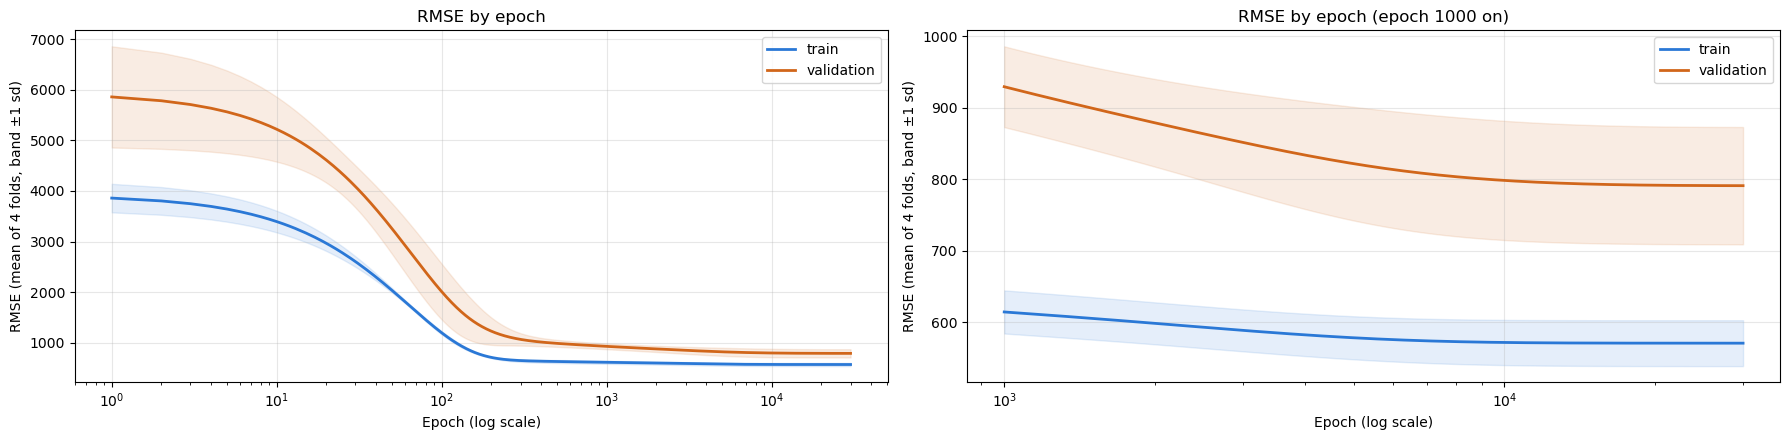

In [26]:
curve = PIPELINES.loss_curve(build(FEATURE_CHOICE, SELECTED_MODEL, scale=True), X=X, y=y, folds=FOLDS, epochs=30_000)

by_epoch = curve.groupby(level="epoch").mean()
print(f"lowest validation rmse: {by_epoch['validation rmse'].min():.3f} at epoch {by_epoch['validation rmse'].idxmin()}")
display(by_epoch.loc[[1, 10, 100, 1000, 3000, 10_000, 20_000, 30_000]].round(3))
PLOTTING.loss_curve(curve=curve, zoom_from=1000, log_x=True);

## Save the Model

The fitted pipeline takes the 11 attributes as they are stored and builds its own feature columns, so it predicts on new rows with no preprocessing outside it.

In [27]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / "linear_regression.joblib"
joblib.dump(final_model, model_path)

reloaded = joblib.load(model_path)
print(f"saved: {model_path.name}")
print(f"reloaded predictions identical: {np.array_equal(reloaded.predict(X), final_model.predict(X))}")

saved: linear_regression.joblib
reloaded predictions identical: True


## Results

- **The selected model is Lasso with `alpha=0.001` and `eta0=0.0001`,** at an rmse of 792.708 over the 4 folds.
- **It does not beat the simpler models.** It ties with plain SGD at the same learning rate (791.910) and is worse than closed form on the same features (789.225, a change of 3.483 against an SE of 1.136). It is selected because the question asks for the best regularized setting, not because the penalty helps.
- **Fit on all 584 rows, it runs 219,994 epochs.** Its training rmse is 613.372, above the 570.165 of the folds, which train on 400 to 538 rows and never on the last 46 days.
- **The loss curve shows no overfitting from training longer.** Validation rmse falls from 5856.281 at epoch 1 to 929.209 at epoch 1,000 and 798.340 at epoch 10,000, and its lowest value is at the last epoch (791.022). Training rmse is flat by then (571.039) and stays well below validation at every epoch, the same gap every model has shown since the Baselines.

**Carry forward**

- **`linear_regression.joblib`,** the fitted pipeline, which reloads with identical predictions. Its cross validated rmse of 792.708 is the estimate for days it has not seen.